# Assignments - Digital options

1. Get familiar with digital options and implement EuropeanDigitalContract and EuropeanDigitalAnalyticPricer (fair value and greeks) in the library. Implement unit test for fair value using pytest. **(12 points)**
2. Get familiar with bull spread options and by utilizing EuropeanDigitalAnalyticPricer and EuropeanAnalyticPricer, create a figure to visualize that a digital call option can be thought of as a limit of bull spread call options. **(8 points)**

## Task 2: Digital Call as the Limit of a Bull Spread

A bull spread strategy can be constructed using a long call option with a lower strike price ($K_1$) and a short call option with a higher strike price ($K_2$). First, let's visualize the static payoff function of this strategy.

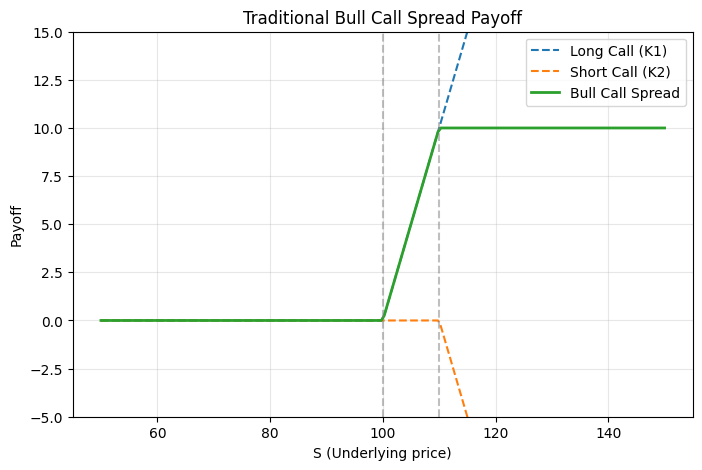

In [1]:
import numpy as np
import matplotlib.pyplot as plt

K1 = 100
K2 = 110

S = np.linspace(50, 150, 200)

long_call = np.maximum(S - K1, 0)
short_call = -np.maximum(S - K2, 0)

bull_spread = long_call + short_call

plt.figure(figsize=(8,5))
plt.plot(S, long_call, '--', label="Long Call (K1)")
plt.plot(S, short_call, '--', label="Short Call (K2)")
plt.plot(S, bull_spread, linewidth=2, label="Bull Call Spread")

plt.axvline(K1, linestyle='--', color='gray', alpha=0.5)
plt.axvline(K2, linestyle='--', color='gray', alpha=0.5)

plt.xlabel("S (Underlying price)")
plt.ylabel("Payoff")
plt.title("Traditional Bull Call Spread Payoff")
plt.ylim(-5, 15)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

If we simply decrease the distance between the two strike prices, the intermediate rising section disappears, but the maximum payoff also tends to $0$. To obtain a digital option (Digital Call) with a payoff of $1$ unit as a limit, we must scale the spread portfolio by a factor of $\frac{1}{\epsilon}$, where $\epsilon = K_2 - K_1$. 

Mathematically, this represents the negative of the derivative of the Call option with respect to the strike price. Thus, as $\epsilon \to 0$, the payoff function becomes a Heaviside step function.

In [ ]:
from ipywidgets import interact, FloatSlider

def plot_bull_spread(epsilon=10.0):
    K1 = 100
    K2 = K1 + epsilon

    S = np.linspace(50, 150, 400)

    long_call = np.maximum(S - K1, 0)
    short_call = -np.maximum(S - K2, 0)
    
    # Scale the payoff by the width of the spread
    bull_spread = (long_call + short_call) / epsilon

    plt.figure(figsize=(8,5))
    plt.plot(S, bull_spread, linewidth=2, label="Scaled Bull Spread")

    plt.xlabel("S (Underlying price)")
    plt.ylabel("Payoff")
    plt.title(f"Scaled Bull Call Spread, $\epsilon$ = {epsilon:.2f}")

    plt.xlim(50, 150)
    plt.ylim(-0.2, 1.2) # The payoff is bounded between 0 and 1
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

interact(
    plot_bull_spread,
    epsilon=FloatSlider(value=10.0, min=0.05, max=20.0, step=0.5)
)

<>:20: SyntaxWarning: invalid escape sequence '\e'
<>:20: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_97338/1496661753.py:20: SyntaxWarning: invalid escape sequence '\e'
  plt.title(f"Scaled Bull Call Spread, $\epsilon$ = {epsilon:.2f}")


interactive(children=(FloatSlider(value=10.0, description='epsilon', max=20.0, min=0.05, step=0.5), Output()),…

<function __main__.plot_bull_spread(epsilon=10.0)>

### Numerical Proof with the Pricer Library

Now let's verify with our Black-Scholes pricer whether the value of the scaled spread converges to the theoretical price of the Digital Call option.

In [3]:
import sys
from pathlib import Path

cwd = Path().resolve()

if cwd.name == "QuantCourseAbraham":
    root_dir = cwd
    hw_dir = cwd / "homeworks" / "40291ac" / "3_building_library_homework"
else:
    hw_dir = cwd
    root_dir = cwd.parents[2]

if str(hw_dir) not in sys.path:
    sys.path.append(str(hw_dir))

if str(root_dir) not in sys.path:
    sys.path.append(str(root_dir))


In [4]:
from pricer import EuropeanAnalyticPricer, EuropeanDigitalAnalyticPricer, Params
from contract import EuropeanContract, EuropeanDigitalContract
from src.enums import Stock, PutCallFwd, LongShort
from market_data import MarketData
from model import MarketModel

underlying = Stock.BLUECHIP_BANK
model = MarketModel(underlying)
params = Params()

K = model.spot
T = 1.0
epsilon = 0.1

# Long Call at K
call_K = EuropeanContract(underlying, PutCallFwd.CALL, LongShort.LONG, K, T)
price_call_K = EuropeanAnalyticPricer(call_K, model, params).calc_fair_value()

# Short Call at K + epsilon
call_K_eps = EuropeanContract(underlying, PutCallFwd.CALL, LongShort.SHORT, K + epsilon, T)
price_call_K_eps = EuropeanAnalyticPricer(call_K_eps, model, params).calc_fair_value()

# Scaled spread approximation (The short call price is already negative, so addition is the net premium)
bull_spread_approx = (price_call_K + price_call_K_eps) / epsilon

# True Digital Call pricing
digital_contract = EuropeanDigitalContract(underlying, PutCallFwd.CALL, LongShort.LONG, K, T)
digital_price = EuropeanDigitalAnalyticPricer(digital_contract, model, params).calc_fair_value()

print(f"Spot = {model.spot:.6f}")
print(f"K = {K:.6f}")
print(f"T = {T:.6f}")
print(f"epsilon = {epsilon:.6f}\n")

print(f"Call(K)                  = {price_call_K:.10f}")
print(f"Call(K+epsilon)          = {price_call_K_eps:.10f}")
print(f"Scaled Bull Spread       = {bull_spread_approx:.10f}")
print(f"Theoretical Digital Call = {digital_price:.10f}")
print(f"Difference (Error)       = {abs(bull_spread_approx - digital_price):.10e}")

QuantCourseBP a668a8bc6f722346da7389ce8feaa16986fa195f*
Spot = 130.170000
K = 130.170000
T = 1.000000
epsilon = 0.100000

Call(K)                  = 22.5240460274
Call(K+epsilon)          = -22.4787704953
Scaled Bull Spread       = 0.4527553208
Theoretical Digital Call = 0.4531371227
Difference (Error)       = 3.8180192137e-04


The difference is the error of the finite difference approximation. If we further decrease the value of $\epsilon$, we can observe the convergence.

<>:19: SyntaxWarning: invalid escape sequence '\e'
<>:19: SyntaxWarning: invalid escape sequence '\e'
/tmp/ipykernel_97338/2300653308.py:19: SyntaxWarning: invalid escape sequence '\e'
  plt.xlabel('$\epsilon$ (Strike difference)')


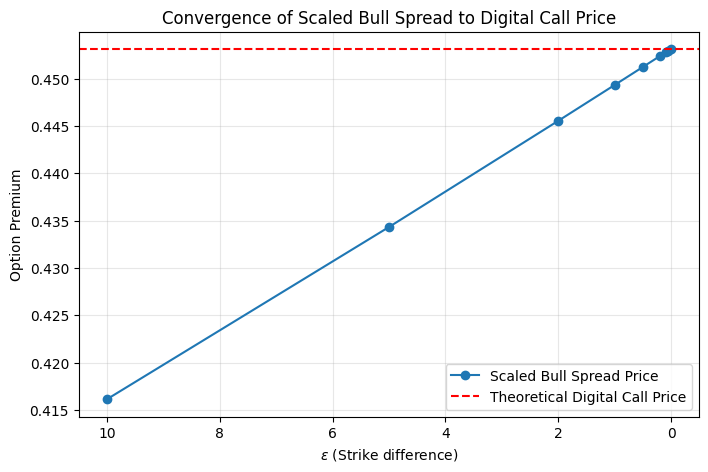

In [5]:
eps_values = np.array([10.0, 5.0, 2.0, 1.0, 0.5, 0.2, 0.1, 0.05, 0.01])
approx_values = []

for eps in eps_values:
    c_long = EuropeanContract(underlying, PutCallFwd.CALL, LongShort.LONG, K, T)
    c_short = EuropeanContract(underlying, PutCallFwd.CALL, LongShort.SHORT, K + eps, T)

    p_long = EuropeanAnalyticPricer(c_long, model, params).calc_fair_value()
    p_short = EuropeanAnalyticPricer(c_short, model, params).calc_fair_value()

    scaled_price = (p_long + p_short) / eps
    approx_values.append(scaled_price)

plt.figure(figsize=(8,5))
plt.plot(eps_values, approx_values, marker='o', label='Scaled Bull Spread Price')
plt.axhline(digital_price, color='red', linestyle='--', label='Theoretical Digital Call Price')

plt.gca().invert_xaxis()
plt.xlabel('$\epsilon$ (Strike difference)')
plt.ylabel('Option Premium')
plt.title('Convergence of Scaled Bull Spread to Digital Call Price')
plt.grid(alpha=0.3)
plt.legend()
plt.show()